# Regime Profiling and Naming
**Purpose:** Describe the final KMeans (k=5) regimes with real-unit profiles, calendar patterns, AQI mix and persistence.

**Inputs:** `data/results/kmeans_labels.csv`, `delhi_features.csv`, `delhi_context.csv`

**Outputs:** `data/results/delhi_regimes.csv`, `data/results/regime_profiles.csv`

## 1. Load the data

In [3]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path.cwd().parent
feat = pd.read_csv(BASE / "data" / "features" / "delhi_features.csv", parse_dates=["Date"], index_col="Date")
ctx = pd.read_csv(BASE / "data" / "features" / "delhi_context.csv", parse_dates=["Date"], index_col="Date")
km = pd.read_csv(BASE / "data" / "results" / "kmeans_labels.csv", parse_dates=["Date"], index_col="Date")["kmeans_cluster"]

names = {0: "Monsoon washout", 1: "Moderate winter smog", 2: "Pre-monsoon dust",
         3: "Severe stagnant winter smog", 4: "Warm, cleaner days"}
colors = {"Monsoon washout": "#2b7bba", "Moderate winter smog": "#f28e2b", "Pre-monsoon dust": "#b07d4f",
          "Severe stagnant winter smog": "#c0392b", "Warm, cleaner days": "#59a14f"}
order = list(names.values())
df = feat.join(ctx).join(km.map(names).rename("regime"))
print(df["regime"].value_counts().loc[order])

regime
Monsoon washout                175
Moderate winter smog           299
Pre-monsoon dust               219
Severe stagnant winter smog    231
Warm, cleaner days             271
Name: count, dtype: int64


## 2. Average profile of each regime (real units)

In [4]:
cols = ["PM2.5", "PM10", "NO", "NO2", "NH3", "SO2", "O3", "CO", "Benzene",
        "PM_ratio", "temp", "rain", "wind_speed", "AQI"]
prof = df.groupby("regime")[cols].mean().loc[order].round(2)
prof["days"] = df["regime"].value_counts().loc[order]
prof["share_%"] = (prof["days"] / len(df) * 100).round(1)
print(prof.T)

regime      Monsoon washout  Moderate winter smog  Pre-monsoon dust  \
PM2.5                 38.32                129.02            111.26   
PM10                  89.84                222.90            288.02   
NO                    14.94                 37.47             48.76   
NO2                   29.16                 49.38             63.35   
NH3                   32.63                 40.36             42.28   
SO2                    9.95                 15.20             25.01   
O3                    29.57                 37.35             49.49   
CO                     0.94                  1.18              1.15   
Benzene                1.87                  3.48              3.55   
PM_ratio               0.44                  0.58              0.39   
temp                  27.36                 17.50             29.65   
rain                   7.59                  0.44              0.23   
wind_speed            15.69                 14.40             18.14   
AQI   

## 3. What makes each regime distinct (standard deviations from the overall mean)

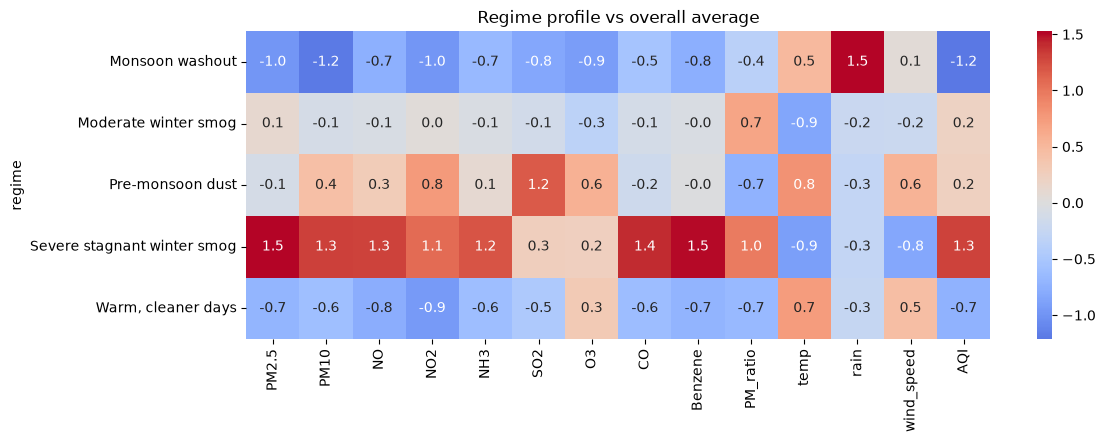

In [5]:
z = (prof[cols] - df[cols].mean()) / df[cols].std()
plt.figure(figsize=(12, 4))
sns.heatmap(z, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Regime profile vs overall average"); plt.show()

## 4. AQI category mix per regime

AQI_cat                      Satisfactory  Moderate  Poor  Very poor  Severe
regime                                                                      
Monsoon washout                      0.47      0.51  0.02       0.01    0.00
Moderate winter smog                 0.00      0.17  0.42       0.36    0.03
Pre-monsoon dust                     0.00      0.10  0.55       0.26    0.08
Severe stagnant winter smog          0.00      0.00  0.02       0.53    0.45
Warm, cleaner days                   0.07      0.71  0.18       0.01    0.02


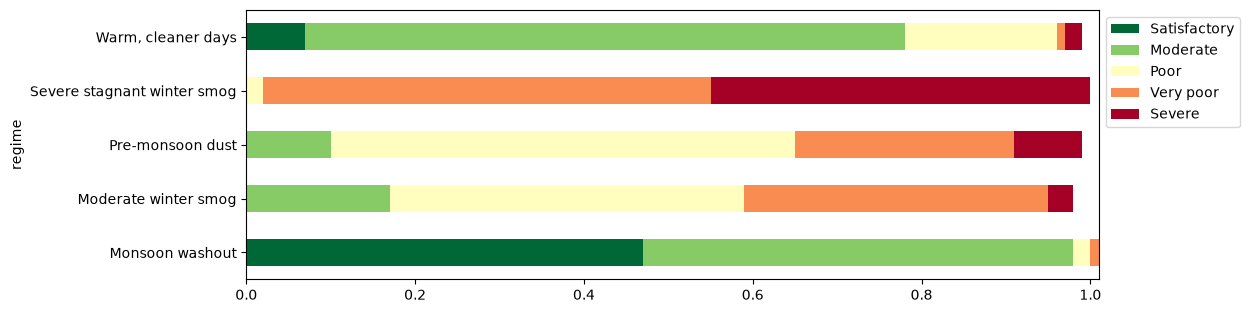

In [6]:
bins = [0, 50, 100, 200, 300, 400, 1000]
labs = ["Good", "Satisfactory", "Moderate", "Poor", "Very poor", "Severe"]
df["AQI_cat"] = pd.cut(df["AQI"], bins=bins, labels=labs)
aqi_mix = pd.crosstab(df["regime"], df["AQI_cat"], normalize="index").loc[order].round(2)
print(aqi_mix)
aqi_mix.plot(kind="barh", stacked=True, figsize=(11, 3.5), colormap="RdYlGn_r"); plt.legend(bbox_to_anchor=(1, 1)); plt.show()

## 5. Which regimes occur in which months

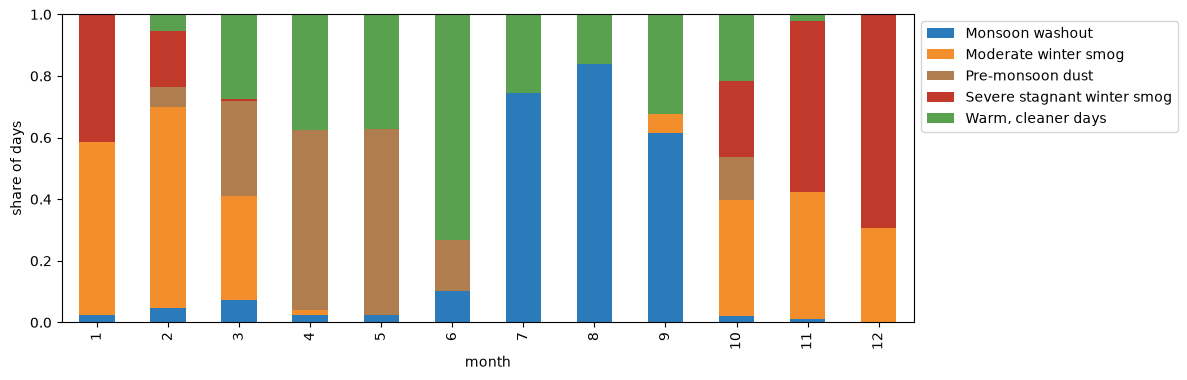

In [7]:
cal = pd.crosstab(df["month"], df["regime"], normalize="index")[order]
cal.plot(kind="bar", stacked=True, figsize=(11, 4), color=[colors[n] for n in order])
plt.ylabel("share of days"); plt.legend(bbox_to_anchor=(1, 1)); plt.show()

## 6. Timeline of regimes, 2016-2020

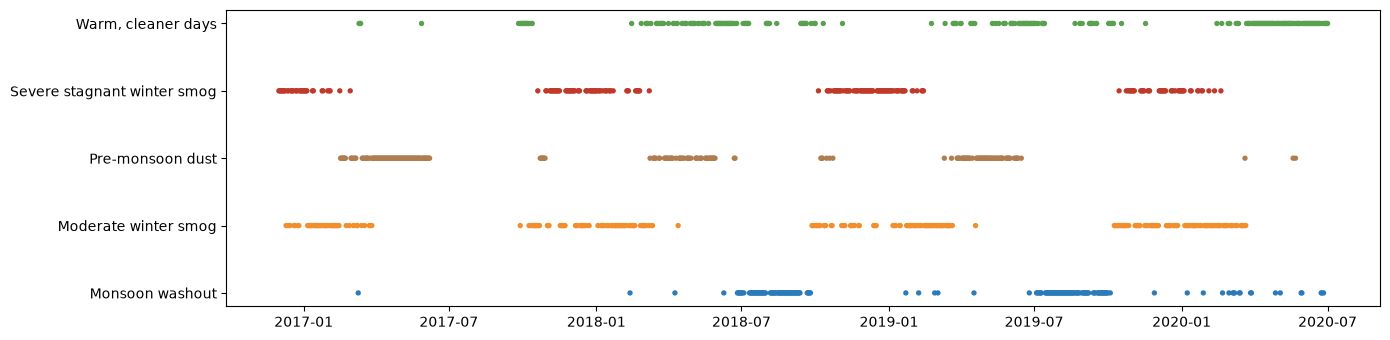

In [8]:
code = df["regime"].map({n: i for i, n in enumerate(order)})
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.scatter(df.index, code, c=df["regime"].map(colors), s=8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
plt.tight_layout(); plt.show()

## 7. Distribution of key variables by regime

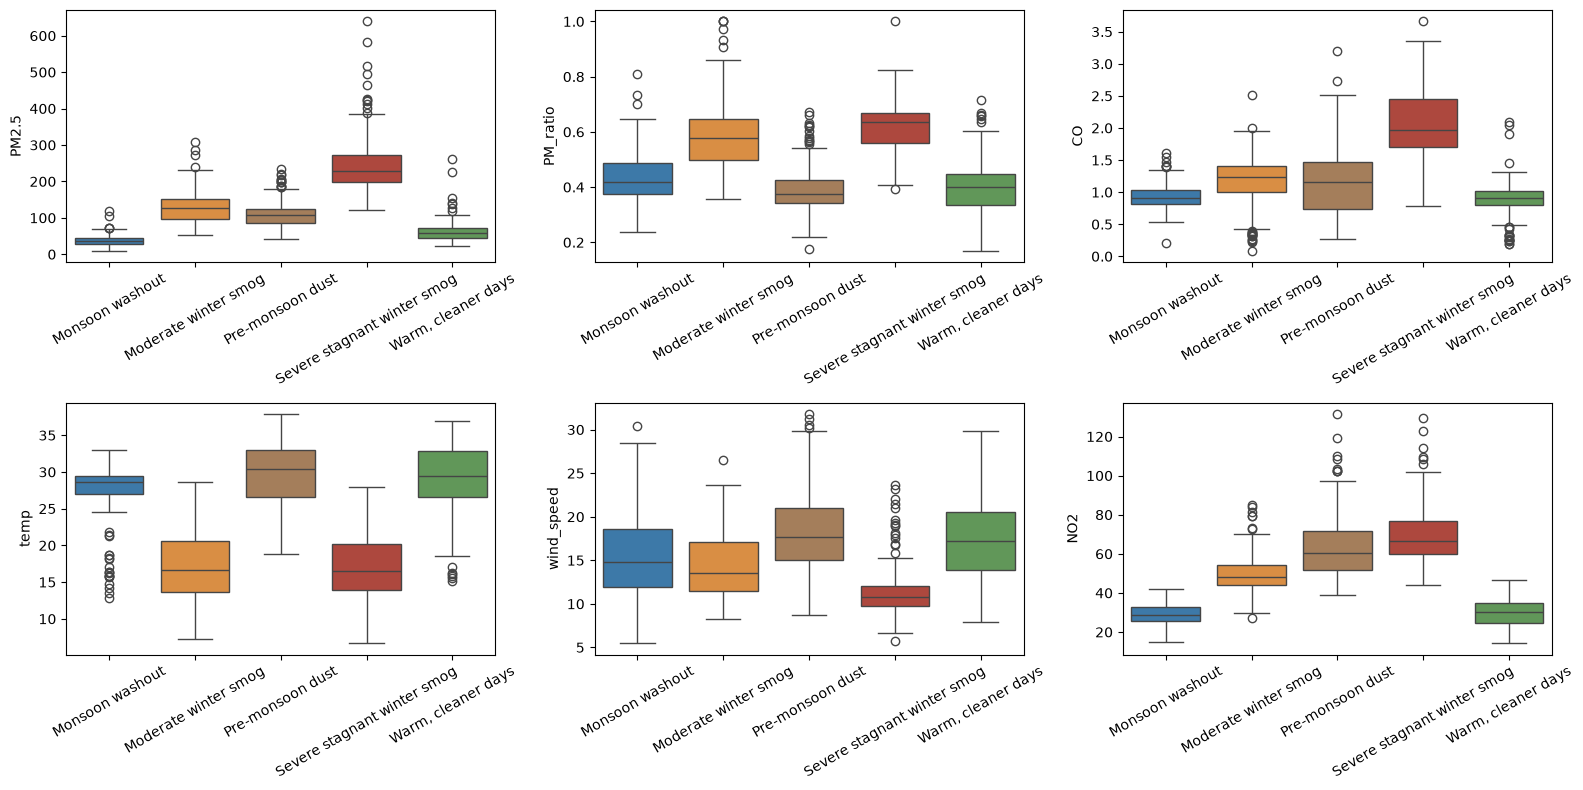

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["PM2.5", "PM_ratio", "CO", "temp", "wind_speed", "NO2"]):
    sns.boxplot(data=df, x="regime", y=c, order=order, hue="regime", palette=colors, legend=False, ax=ax)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 8. Regime share by year
(2016 is December only and 2020 is January to July, so compare 2018 and 2019 directly)

In [10]:
print(pd.crosstab(df["year"], df["regime"], normalize="index")[order].round(2))
print(pd.crosstab(df["year"], df["regime"]).loc[:, order])

regime  Monsoon washout  Moderate winter smog  Pre-monsoon dust  \
year                                                              
2016               0.00                  0.26              0.00   
2017               0.00                  0.30              0.40   
2018               0.20                  0.19              0.15   
2019               0.22                  0.27              0.17   
2020               0.10                  0.28              0.02   

regime  Severe stagnant winter smog  Warm, cleaner days  
year                                                     
2016                           0.74                0.00  
2017                           0.22                0.08  
2018                           0.22                0.24  
2019                           0.16                0.19  
2020                           0.07                0.54  
regime  Monsoon washout  Moderate winter smog  Pre-monsoon dust  \
year                                                     

## 9. How long does a regime last? (consecutive days)

In [11]:
gap = df.index.to_series().diff().dt.days != 1       # break runs at removed days
runs = ((df["regime"] != df["regime"].shift()) | gap).cumsum()
run_len = df.groupby(["regime", runs]).size().groupby("regime").agg(["mean", "median", "max"]).loc[order].round(1)
print(run_len)

                             mean  median  max
regime                                        
Monsoon washout               4.6     1.0   37
Moderate winter smog          3.2     2.0   16
Pre-monsoon dust              5.0     3.0   61
Severe stagnant winter smog   4.0     2.5   20
Warm, cleaner days            3.6     2.0   29


## 10. Save labelled data and profiles

In [12]:
out = df[["regime"] + cols + ["year", "month"]]
out.to_csv(BASE / "data" / "results" / "delhi_regimes.csv")
prof.to_csv(BASE / "data" / "results" / "regime_profiles.csv")
print("saved", out.shape)

saved (1195, 17)


## Conclusion
| Regime | Days | Typical conditions | AQI mix |
|---|---|---|---|
| Monsoon washout | 175 (14.6%) | Rain 7.6 mm, PM2.5 38, 27 °C | 98% Satisfactory or Moderate |
| Moderate winter smog | 299 (25.0%) | PM2.5 129, 17.5 °C, dry | 78% Poor or Very poor |
| Pre-monsoon dust | 219 (18.3%) | PM10 288, PM2.5/PM10 0.39, windiest, 29.7 °C | 81% Poor or Very poor, 8% Severe |
| Severe stagnant winter smog | 231 (19.3%) | PM2.5 245, CO 2.1, Benzene 7.0, calmest wind, 17 °C | 98% Very poor or Severe |
| Warm, cleaner days | 271 (22.7%) | PM2.5 61, PM10 163, 29 °C | 71% Moderate |

The names are interpretations of the profiles. The dust label rests on the low fine-to-coarse particle ratio, high wind and hot, dry months, with no direct dust measurement. "Cleaner" is relative to winter, and most of those days are still Moderate on the AQI scale.

**By year.** 2018 and 2019 (the two full years) have similar regime mixes, so the regimes repeat from year to year. 2017 has almost no monsoon days (the outage removed them) and an unusually high dust share (40%). 2020 is 54% "Warm, cleaner days" and 2% dust (January to July only).

**Persistence.** Regimes last 3 to 5 days on average, but the median run is only 1 to 3 days, with a few long runs (up to 61 days for dust). Days switch between neighbouring regimes often, so a regime is best read as the dominant condition of a period.